# Risk Prediction
### End-to-End Exploratory Data Analysis, Feature Engineering, and Machine Learning Pipeline

* **Data Source:** [UCI Machine Learning Repository - Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/default?)
* **Reference & Documentation:** [Dataset Details & Guide](https://inseaddataanalytics.github.io/INSEADAnalytics/CourseSessions/ClassificationProcessCreditCardDefault.html)

---

### Notebook Overview
1. **Data Exploration & Cleaning:** Fetching data from the UCI repository, cleaning categorical features (Education, Sex), and renaming columns based on the data dictionary.
2. **Feature Engineering:** Creating time-agnostic metrics like `on_time_payment_rate`, `avg_payment_delay`, and `avg_credit_utilization` to make payment histories more flexible.
3. **Model Training & Comparison:** Training and evaluating baseline models (Logistic Regression, Random Forest, Base XGBoost, and SVM) using stratified splits and class balancing.
4. **Hyperparameter Tuning & Final Evaluation:** Optimizing XGBoost via `GridSearchCV` (focusing on recall) and evaluating final performance on unseen test data with detailed confusion matrices and metrics.

### Exploration of Data and training of Model using the Dataset from [UC ML REPO](https://archive.ics.uci.edu/dataset/350/default?)

### Details about the dataset can be found at the [link](https://inseaddataanalytics.github.io/INSEADAnalytics/CourseSessions/ClassificationProcessCreditCardDefault.html)

## Import the required libraries for data handling, visualization, scientific computing, and machine learning, and install the package needed to fetch the dataset from UCI.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import scipy
import sklearn

## Fetch the Default of Credit Card Clients dataset (UCI ID 350) for data exploration and model development.Separate the input features and target

In [2]:
from pathlib import Path

# The local copy (the UCI data plus an EMAIL column) is used when it is there, so the notebook
# runs offline and its customer IDs match the backend's. Otherwise the data comes from UCI.
LOCAL_DATA = Path("../default_of_credit_card_clients.xls")
dataset = None
if LOCAL_DATA.is_file():
    df = pd.read_excel(LOCAL_DATA, header=1)  # row 1 is X1..X23; row 2 has the column names
    df = df.drop(columns=["EMAIL"], errors="ignore")
else:
    from ucimlrepo import fetch_ucirepo  # pip install ucimlrepo

    dataset = fetch_ucirepo(id=350)  # UCI ID 350 = Default of Credit Card Clients
    df = pd.concat([dataset.data.features, dataset.data.targets], axis=1)
    df.insert(0, "ID", range(1, len(df) + 1))  # the UCI rows are in ID order

# The ID identifies the customer; it is kept aside, never used as a model input.
customer_ids = df.pop("ID")
print(df.shape)
df.head()

C:\Users\MSheharzadSalahuddin\AppData\Local\Temp\ipykernel_25104\4173455057.py:8: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(LOCAL_DATA, header=1)  # row 1 is X1..X23; row 2 has the column names


(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:
if dataset is not None:
    print(dataset.metadata)

In [4]:
dataset.variables if dataset is not None else None

## Rename technical column names to human-readable descriptions
# using the dataset's metadata dictionary for easier interpretation.

In [5]:
# Columns from UCI are named X1..X23 and Y; their descriptions are the names used below.
# The local file already has those names.
if dataset is not None:
    rename_map = dataset.variables.set_index("name")["description"].dropna().to_dict()
    df = df.rename(columns=rename_map)

df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


# Select key behavioral and financial features for analysis and visualization

In [6]:
cols = [
    "LIMIT_BAL",
    "AGE",
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
    "BILL_AMT1", "BILL_AMT2", "BILL_AMT3",
    "BILL_AMT4", "BILL_AMT5", "BILL_AMT6",
    "PAY_AMT1", "PAY_AMT2", "PAY_AMT3",
    "PAY_AMT4", "PAY_AMT5", "PAY_AMT6",
    "default payment next month"
]



# Calculate correlations between selected features and plot a heatmap

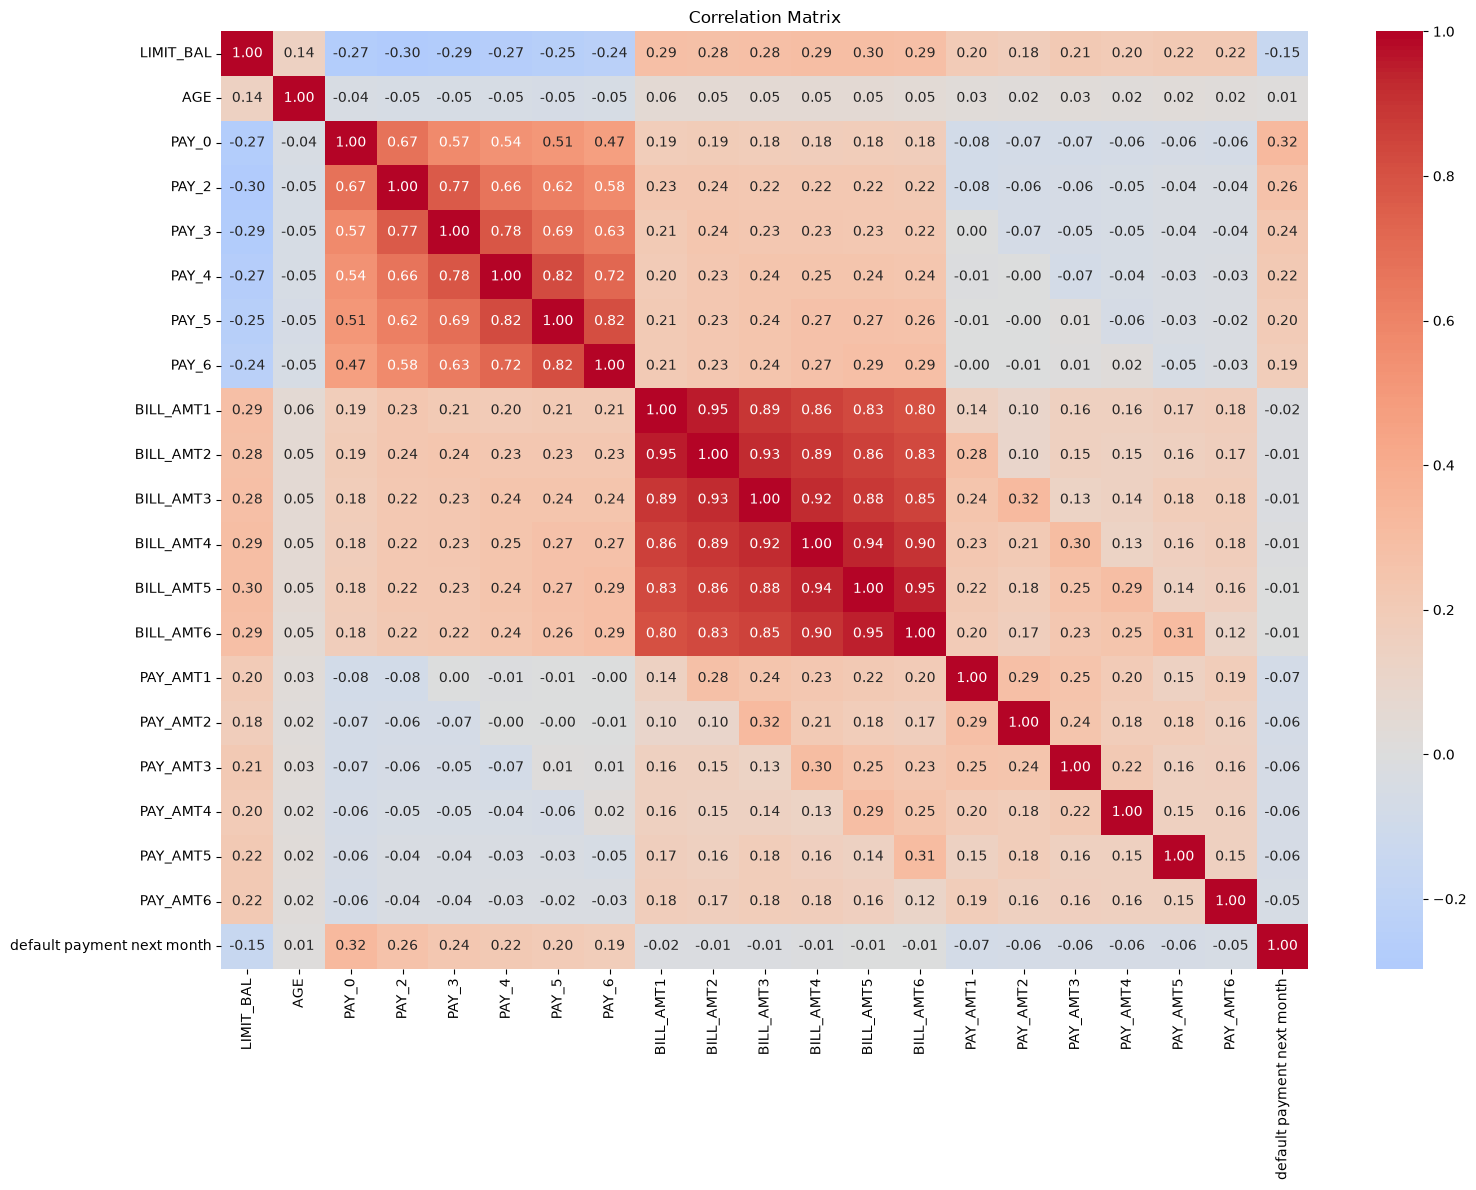

In [7]:
# Correlation matrix
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 12))

corr = df[cols].corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

# Check the count and percentage breakdown of the target variable (default status)

In [8]:
print(df["default payment next month"].value_counts())
print(df["default payment next month"].value_counts(normalize=True) * 100)

default payment next month
0    23364
1     6636
Name: count, dtype: int64
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


# Plot a bar chart showing the distribution of the target variable (default vs. non-default)

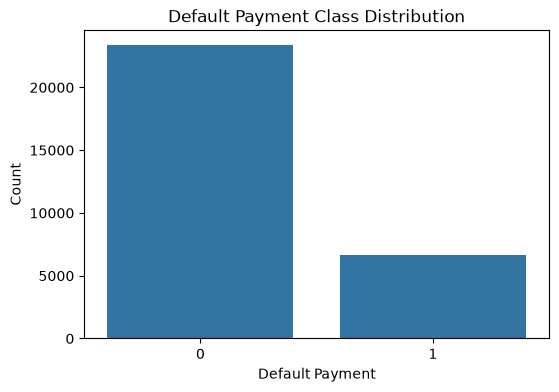

In [9]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="default payment next month")

plt.title("Default Payment Class Distribution")
plt.xlabel("Default Payment")
plt.ylabel("Count")
plt.show()

# These represent how late the borrower was in making payments for each month.
# -1 = pay duly; 1 = payment delay for one month; 2 = payment delay for two months; . . .; 8 = payment delay for eight months;
# 9 = payment delay for nine months and above.

# Repayment status in September, 2005 (-2=no consumption, -1=pay duly,
# 0=the use of revolving credit, 1=payment delay for one month,
# 2=payment delay for two months, … 8=payment delay for eight months,
# 9=payment delay for nine months and above)
# Second Def Source



In [10]:
pay_cols = [
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

# Calculate the default rate for each payment status column and plot line charts
#It calculates the average default rate for each category in payment columns and draws line charts to show how payment behavior affects the likelihood of defaulting.

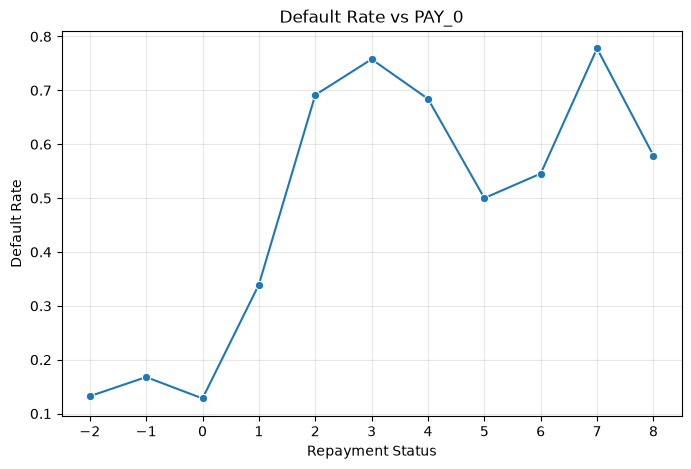

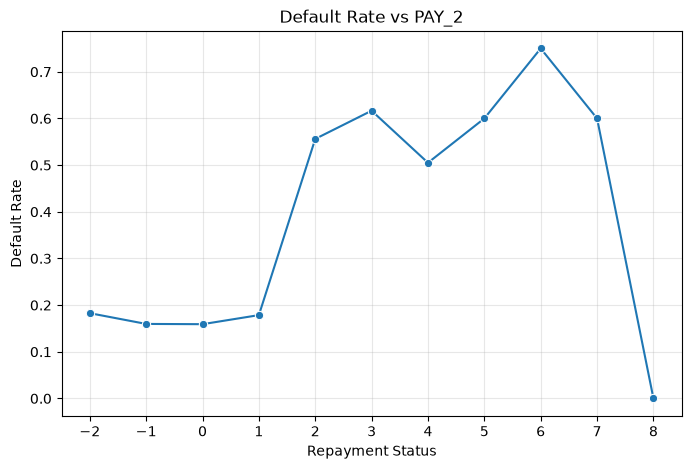

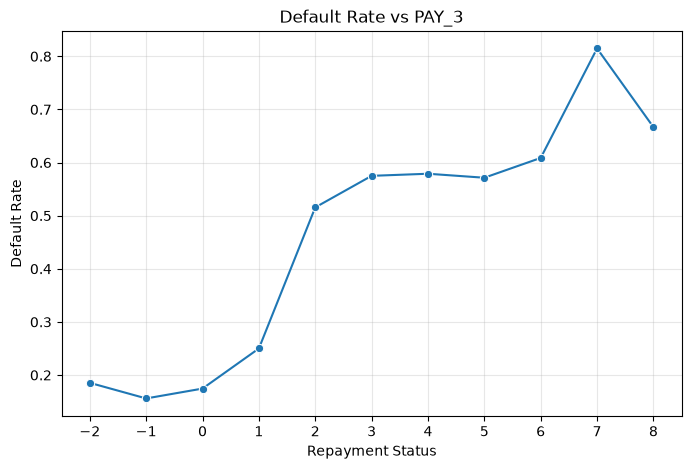

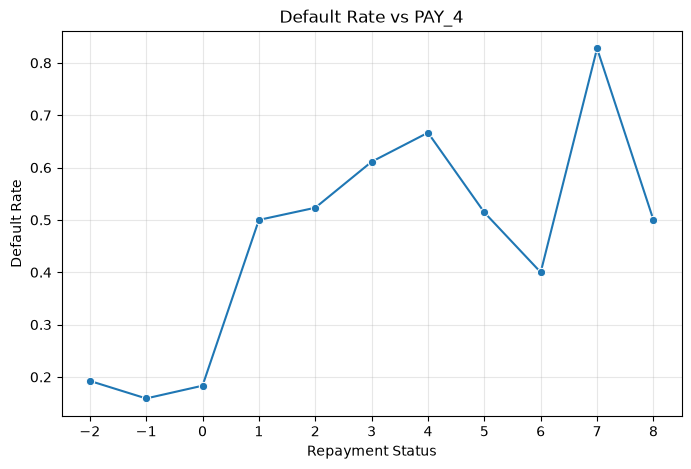

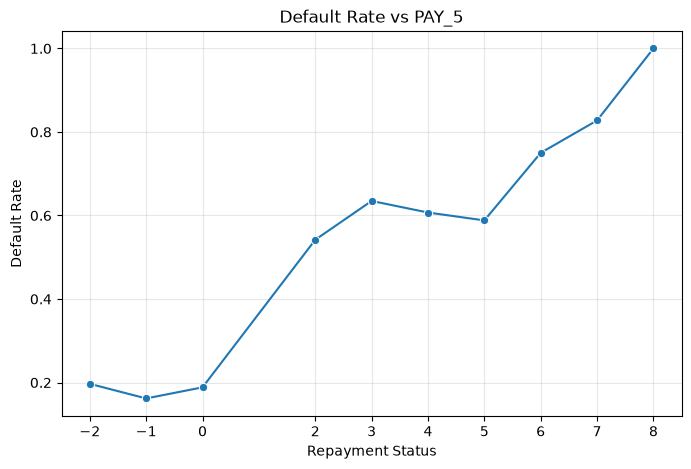

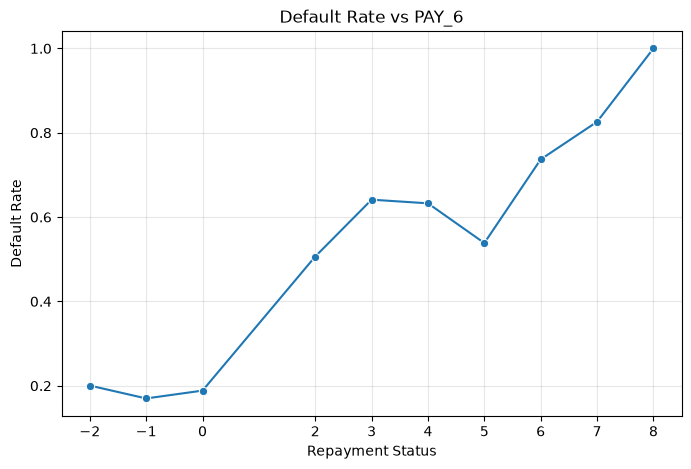

In [11]:
target = "default payment next month"

for col in pay_cols:
    default_rate = (
        df.groupby(col)[target]
        .mean()
        .reset_index()
    )

    plt.figure(figsize=(8, 5))

    sns.lineplot(
        data=default_rate,
        x=col,
        y=target,
        marker="o"
    )

    plt.title(f"Default Rate vs {col}")
    plt.xlabel("Repayment Status")
    plt.ylabel("Default Rate")
    plt.xticks(sorted(df[col].unique()))
    plt.grid(True, alpha=0.3)

    plt.show()

# All the pay columns show that the default rate increases as the late payments in earlier payments

#Trying to create universal features from the timesteps so we can make this time agnsotic

In [12]:
valid_payments = (df[pay_cols] != -2) & (df[pay_cols] != 0)
valid_payments

df["on_time_payment_rate"] = (
    (df[pay_cols] == -1).sum(axis=1)
    / valid_payments.sum(axis=1)
)
# 0 / 0 (no month that counts) is NaN; such customers never paid late, so the rate is 1.
# (An assignment: pandas 3 ignores a chained fillna(..., inplace=True).)
df["on_time_payment_rate"] = df["on_time_payment_rate"].fillna(1)
df["on_time_payment_rate"].describe()


count    30000.000000
mean         0.724204
std          0.424534
min          0.000000
25%          0.333333
50%          1.000000
75%          1.000000
max          1.000000
Name: on_time_payment_rate, dtype: float64

# Calculate the default rate percentage by on-time payment rate and plot a line chart

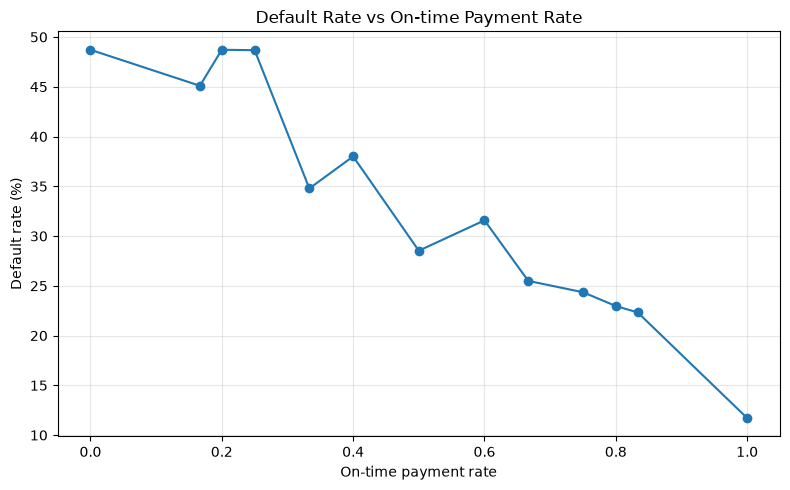

In [13]:
import matplotlib.pyplot as plt

grouped = df.groupby("on_time_payment_rate")["default payment next month"].agg(
    default_rate="mean",
    count="size"
).reset_index()

plt.figure(figsize=(8, 5))
plt.plot(
    grouped["on_time_payment_rate"],
    grouped["default_rate"] * 100,
    marker="o"
)
plt.xlabel("On-time payment rate")
plt.ylabel("Default rate (%)")
plt.title("Default Rate vs On-time Payment Rate")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Calculate the correlation coefficient between on-time payment rate and default status

In [14]:
df["on_time_payment_rate"].corr(df["default payment next month"])

np.float64(-0.37883725884512215)

# Plot a histogram with a density curve comparing on-time payment rates by default status

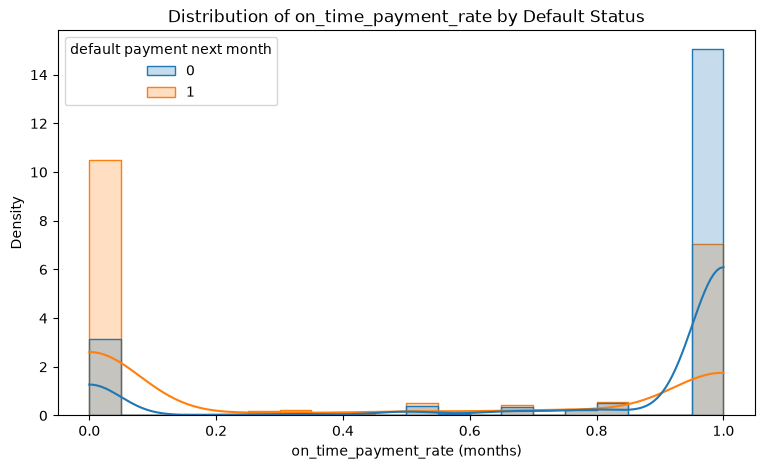

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="on_time_payment_rate",
    hue="default payment next month",
    bins=20,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.xlabel("on_time_payment_rate (months)")
plt.ylabel("Density")
plt.title("Distribution of on_time_payment_rate by Default Status")
plt.show()

# This chart shows that the time agnostic features captures more or less the same information i.e the default rate decreases when on time rate increases as was our hypothesis we will drop the pay_0-pay_6 cols
#### With this our model is now extendable to capture more information even if we have a payment history of N months where n is any number from 1-infinity


# Calculate the average payment delay across all months (ignoring early payments by setting them to 0)

In [16]:
# Average payment delay
delay_values = df[pay_cols].copy()

delay_values = delay_values.clip(lower=0)

df["avg_payment_delay"] = delay_values.mean(axis=1)

# Calculate the correlation between average payment delay and default status

In [17]:
df["avg_payment_delay"].corr(df["default payment next month"])

np.float64(0.37603366963462725)

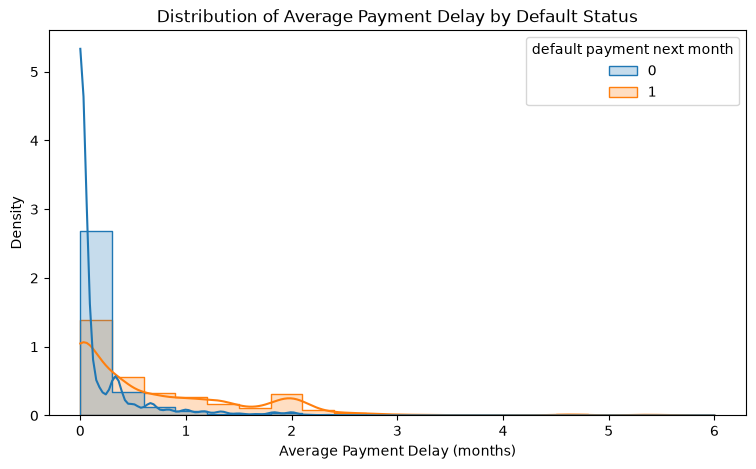

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="avg_payment_delay",
    hue="default payment next month",
    bins=20,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.xlabel("Average Payment Delay (months)")
plt.ylabel("Density")
plt.title("Distribution of Average Payment Delay by Default Status")
plt.show()

## Bill Cols

In [19]:
bill_cols = [
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6"
]
payment_cols = [
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6"
]

In [20]:
df['avg_credit_utilization'] = df[bill_cols].div(df['LIMIT_BAL'], axis=0).mean(axis=1)

In [21]:
df['avg_credit_utilization'].describe()

count    30000.000000
mean         0.373048
std          0.351890
min         -0.232590
25%          0.029997
50%          0.284834
75%          0.687929
max          5.364308
Name: avg_credit_utilization, dtype: float64

# Plot a detailed histogram comparing the distribution of average credit utilization by default status

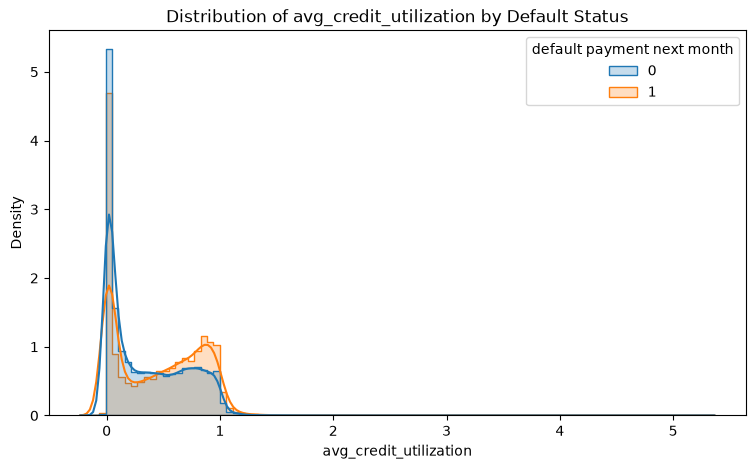

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="avg_credit_utilization",
    hue="default payment next month",
    bins=100,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.xlabel("avg_credit_utilization")
plt.ylabel("Density")
plt.title("Distribution of avg_credit_utilization by Default Status")
plt.show()

In [23]:
df["avg_credit_utilization"].corr(df["default payment next month"])

np.float64(0.11548285326428635)

In [24]:
df = df.drop(columns=bill_cols + payment_cols+pay_cols)

# Calculates the average default rate for each education level and draws a bar chart to compare how education background affects the likelihood of defaulting.

C:\Users\MSheharzadSalahuddin\AppData\Local\Temp\ipykernel_25104\3114321988.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=edu_default, x='EDUCATION', y='default payment next month', palette='Blues_d')


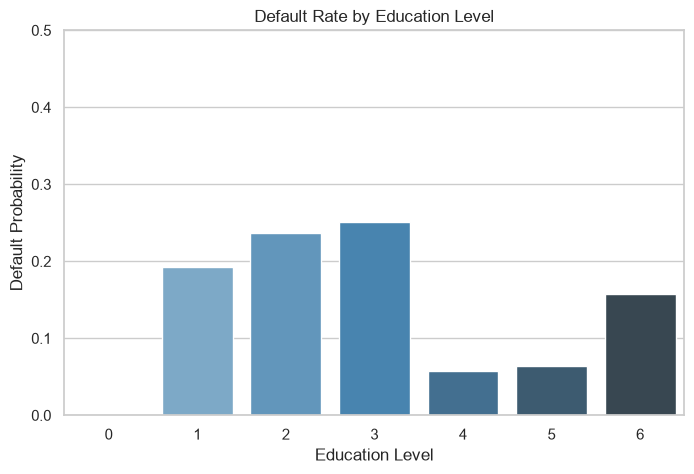

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# 1. Education vs. Default Rate
plt.figure(figsize=(8, 5))
edu_default = df.groupby('EDUCATION')['default payment next month'].mean().reset_index()

# Map labels if needed based on data dictionary (1=grad school, 2=university, 3=high school, 4=others)
sns.barplot(data=edu_default, x='EDUCATION', y='default payment next month', palette='Blues_d')
plt.title('Default Rate by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Default Probability')
plt.ylim(0, 0.5)
plt.show()

# Groups rare or unusual education categories together, maps them to clear text labels (like Graduate School, University, High School, and Other), and draws a clean bar chart showing the default rate for each group.

C:\Users\MSheharzadSalahuddin\AppData\Local\Temp\ipykernel_25104\3597777576.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=edu_default, x='EDUCATION_LABEL', y='default payment next month', palette='Blues_d')


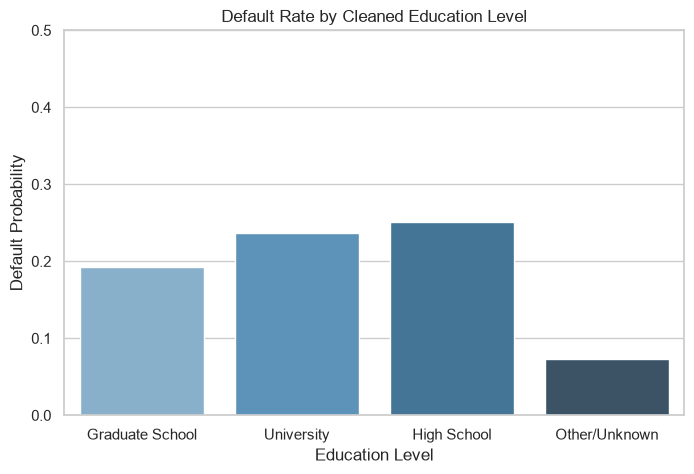

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Group education levels 4, 5, and 6 together into category 4
df['EDUCATION_cleaned'] = df['EDUCATION'].replace({5: 4, 6: 4})

# Calculate default rate by the cleaned education feature
plt.figure(figsize=(8, 5))
edu_default = df.groupby('EDUCATION_cleaned')['default payment next month'].mean().reset_index()

# Optional: Map labels for readability
edu_labels = {1: 'Graduate School', 2: 'University', 3: 'High School', 4: 'Other/Unknown'}
edu_default['EDUCATION_LABEL'] = edu_default['EDUCATION_cleaned'].map(edu_labels)

sns.barplot(data=edu_default, x='EDUCATION_LABEL', y='default payment next month', palette='Blues_d')
plt.title('Default Rate by Cleaned Education Level')
plt.xlabel('Education Level')
plt.ylabel('Default Probability')
plt.ylim(0, 0.5)
plt.show()

# calculates the average default rate for each gender category and draws a bar chart to compare how gender affects the likelihood of defaulting.

C:\Users\MSheharzadSalahuddin\AppData\Local\Temp\ipykernel_25104\798020630.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=edu_default, x='SEX', y='default payment next month', palette='Blues_d')


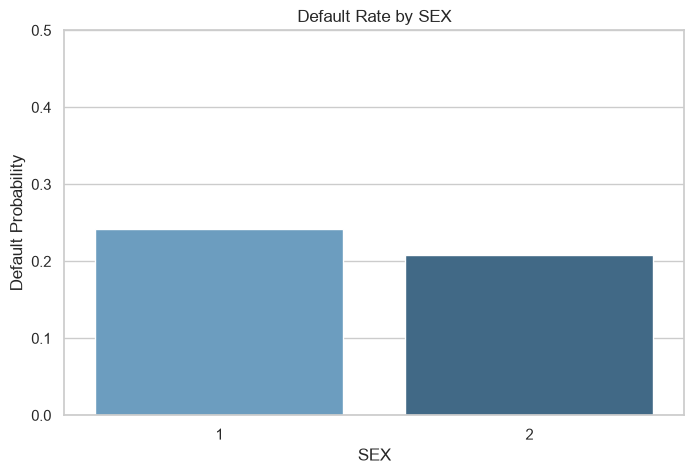

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# 1. Education vs. Default Rate
plt.figure(figsize=(8, 5))
edu_default = df.groupby('SEX')['default payment next month'].mean().reset_index()

# Map labels if needed based on data dictionary (1=grad school, 2=university, 3=high school, 4=others)
sns.barplot(data=edu_default, x='SEX', y='default payment next month', palette='Blues_d')
plt.title('Default Rate by SEX')
plt.xlabel('SEX')
plt.ylabel('Default Probability')
plt.ylim(0, 0.5)
plt.show()

In [28]:
df['sex_male'] = (df['SEX'] == 1)
df['sex_female'] = (df['SEX'] == 2)

In [29]:
df.drop(columns='SEX',inplace=True)
df.drop(columns="MARRIAGE",inplace=True)

C:\Users\MSheharzadSalahuddin\AppData\Local\Temp\ipykernel_25104\3268665026.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns='SEX',inplace=True)
C:\Users\MSheharzadSalahuddin\AppData\Local\Temp\ipykernel_25104\3268665026.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns="MARRIAGE",inplace=True)


# calculates the average default rate for every single age (from the  to the oldest customer) and draws a line chart to show how age trends relate to the risk of defaulting.

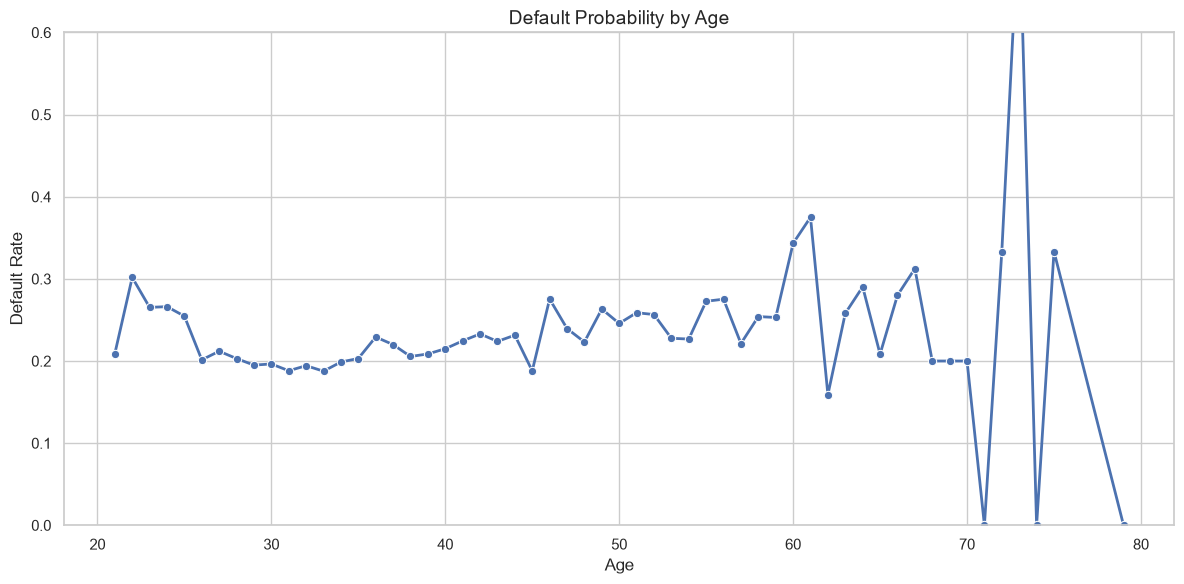

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Calculate default rate by exact age
age_default = df.groupby('AGE')['default payment next month'].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=age_default, x='AGE', y='default payment next month', marker='o', color='b', linewidth=2)

plt.title('Default Probability by Age', fontsize=14)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Default Rate', fontsize=12)
plt.ylim(0, 0.6)
plt.tight_layout()
plt.show()

# Calculates the correlation between every single column in your entire dataset, and draws a large, detailed heatmap to show how all the features relate to each other.

# Drop redundant or replaced columns from the dataframe

In [31]:
df.drop(columns=['sex_female','EDUCATION'],inplace=True)

C:\Users\MSheharzadSalahuddin\AppData\Local\Temp\ipykernel_25104\3297410819.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['sex_female','EDUCATION'],inplace=True)


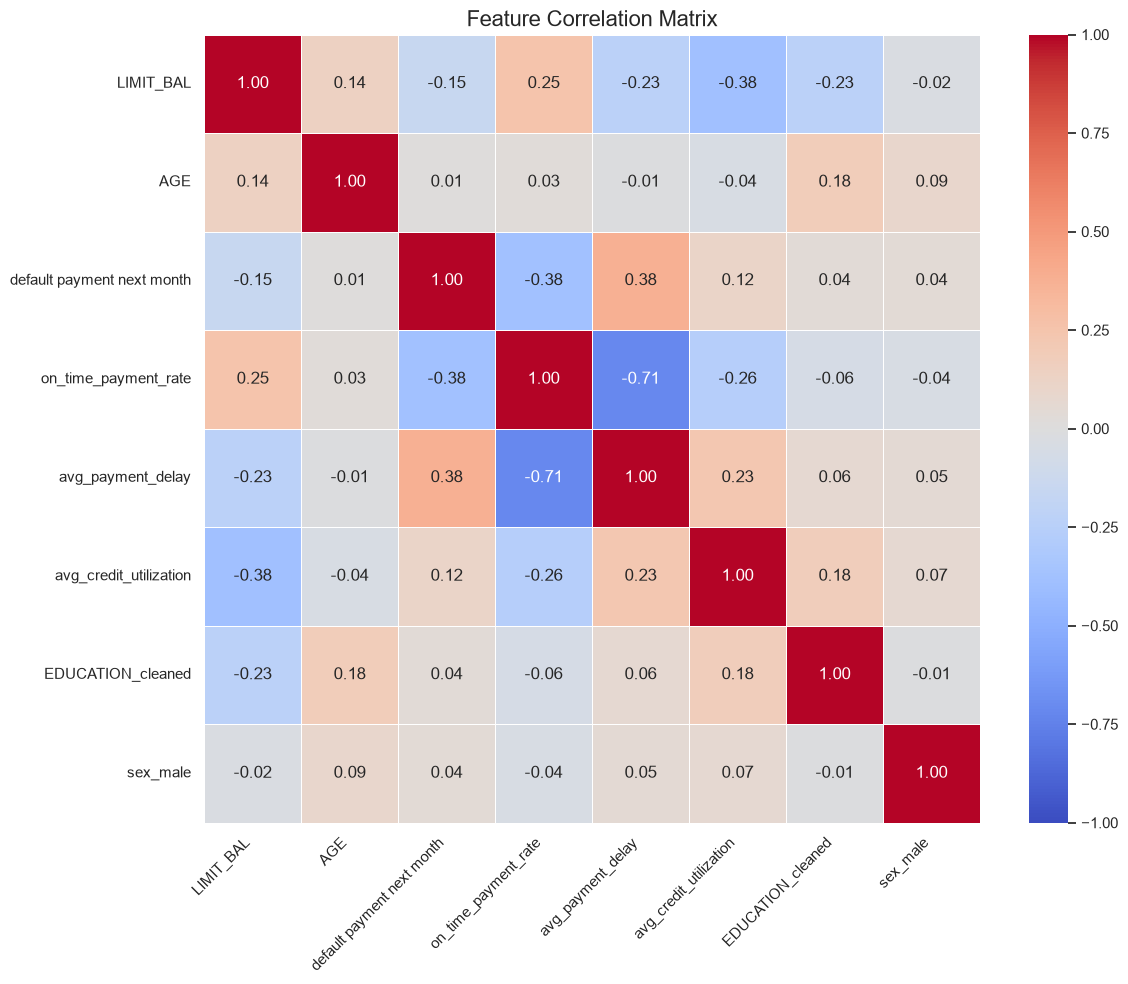

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the figure
plt.figure(figsize=(12, 10))

# Calculate the correlation matrix
corr_matrix = df.corr()

# Create a mask to hide the upper triangle for a cleaner look (optional)
# mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Draw the heatmap
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title('Feature Correlation Matrix', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Model Train

## Train-Validation-Test Split

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Separate features and target
X = df.drop(columns=["default payment next month"])
y = df["default payment next month"]

# First split: 85% temporary data, 15% testing data
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Second split: 70% training, 15% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.17647,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

Training set: (21000, 7)
Validation set: (4500, 7)
Testing set: (4500, 7)


### Compute Class Weights for Imbalanced Data

Calculates custom weights for your target classes so the model pays equal attention to the minority class (defaults) and doesn't get biased toward the majority non-default class.

In [34]:
from sklearn.utils.class_weight import compute_class_weight

y = df['default payment next month']
classes = np.unique(y)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y)
class_weight_dict = dict(zip(classes, weights))

In [35]:
class_weight_dict

{np.int64(0): np.float64(0.6420133538777607),
 np.int64(1): np.float64(2.2603978300180834)}

# LOGISTIC REGRESSION

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

# Build the pipeline with scaler and logistic regression
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42,
        class_weight=class_weight_dict
    ))
])

# Train
logistic_pipeline.fit(X_train, y_train)

# Validation predictions
y_val_pred_log = logistic_pipeline.predict(X_val)
y_val_prob_log = logistic_pipeline.predict_proba(X_val)[:, 1]

# Validation evaluation
print("Logistic Regression (Pipeline) - Validation Results")
print("-----------------------------------")
print("Accuracy :", accuracy_score(y_val, y_val_pred_log))
print("Precision:", precision_score(y_val, y_val_pred_log))
print("Recall   :", recall_score(y_val, y_val_pred_log))
print("F1 Score :", f1_score(y_val, y_val_pred_log))
print("ROC-AUC  :", roc_auc_score(y_val, y_val_prob_log))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_log))

Logistic Regression (Pipeline) - Validation Results
-----------------------------------
Accuracy : 0.7664444444444445
Precision: 0.47752808988764045
Recall   : 0.5979899497487438
F1 Score : 0.5310129406514948
ROC-AUC  : 0.7524608778557552

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.81      0.84      3505
           1       0.48      0.60      0.53       995

    accuracy                           0.77      4500
   macro avg       0.68      0.71      0.69      4500
weighted avg       0.79      0.77      0.78      4500



# Logistic Regression Confusion Matrix

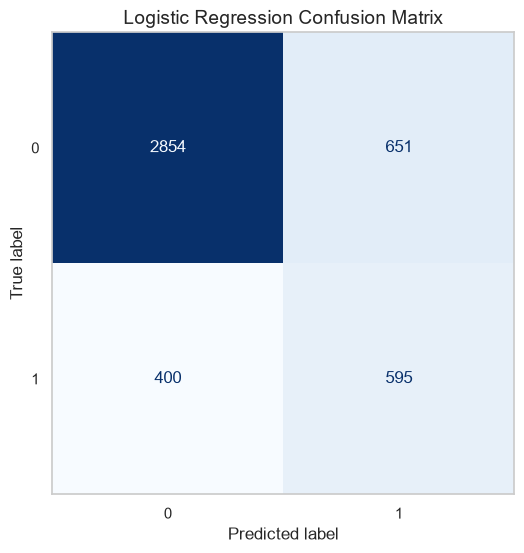

In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_log,
    display_labels=[0, 1],
    cmap='Blues',
    colorbar=False,
    ax=plt.gca()
)
plt.title('Logistic Regression Confusion Matrix', fontsize=14)
plt.grid(False)
plt.show()

# RandomForest

In [38]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

# Build the pipeline with scaler and random forest
rf_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
        class_weight=class_weight_dict
    ))
])

# Train
rf_pipeline.fit(X_train, y_train)

# Validation predictions
y_val_pred = rf_pipeline.predict(X_val)
y_val_prob = rf_pipeline.predict_proba(X_val)[:, 1]

# Validation evaluation
print("Random Forest (Pipeline) - Validation Results")
print("-----------------------------------")
print("Accuracy :", accuracy_score(y_val, y_val_pred))
print("Precision:", precision_score(y_val, y_val_pred))
print("Recall   :", recall_score(y_val, y_val_pred))
print("F1 Score :", f1_score(y_val, y_val_pred))
print("ROC-AUC  :", roc_auc_score(y_val, y_val_prob))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

Random Forest (Pipeline) - Validation Results
-----------------------------------
Accuracy : 0.7597777777777778
Precision: 0.4606946983546618
Recall   : 0.5065326633165829
F1 Score : 0.48252752513164193
ROC-AUC  : 0.7319719854622613

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.83      0.84      3505
           1       0.46      0.51      0.48       995

    accuracy                           0.76      4500
   macro avg       0.66      0.67      0.66      4500
weighted avg       0.77      0.76      0.76      4500



# Random Forest Confusion Matrix

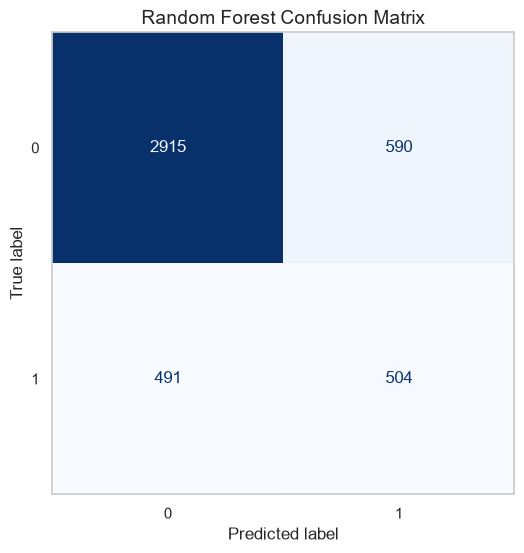

In [39]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    display_labels=[0, 1],
    cmap='Blues',
    colorbar=False,
    ax=plt.gca()
)
plt.title('Random Forest Confusion Matrix', fontsize=14)
plt.grid(False)
plt.show()

# XGBoost Model

In [40]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

# Ensure scale_pos_weight_val is calculated
scale_pos_weight_val = (y_train == 0).sum() / (y_train == 1).sum()

# Build the pipeline with scaler and tuned XGBoost
xgb_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", XGBClassifier(
        n_estimators=500,
        learning_rate=0.01,
        scale_pos_weight=scale_pos_weight_val,
        random_state=42,
        n_jobs=-1
    ))
])

# Train
xgb_pipeline.fit(X_train, y_train)

# Validation predictions
y_val_pred_xgb = xgb_pipeline.predict(X_val)
y_val_prob_xgb = xgb_pipeline.predict_proba(X_val)[:, 1]

# Validation evaluation
print("Tuned XGBoost (Pipeline) - Validation Results")
print("-----------------------------------")
print("Accuracy :", accuracy_score(y_val, y_val_pred_xgb))
print("Precision:", precision_score(y_val, y_val_pred_xgb))
print("Recall   :", recall_score(y_val, y_val_pred_xgb))
print("F1 Score :", f1_score(y_val, y_val_pred_xgb))
print("ROC-AUC  :", roc_auc_score(y_val, y_val_prob_xgb))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_xgb))

Tuned XGBoost (Pipeline) - Validation Results
-----------------------------------
Accuracy : 0.7522222222222222
Precision: 0.45652173913043476
Recall   : 0.6331658291457286
F1 Score : 0.5305263157894737
ROC-AUC  : 0.7732015283263679

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.79      0.83      3505
           1       0.46      0.63      0.53       995

    accuracy                           0.75      4500
   macro avg       0.67      0.71      0.68      4500
weighted avg       0.79      0.75      0.77      4500



# xgb_pipeline Confusion Matrix

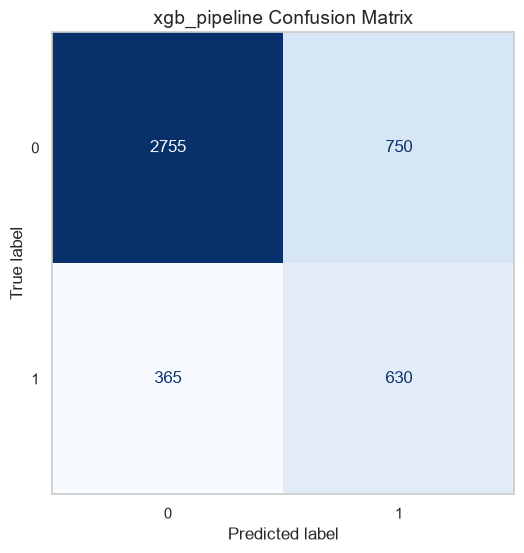

In [41]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_xgb,
    display_labels=[0, 1],
    cmap='Blues',
    colorbar=False,
    ax=plt.gca()
)
plt.title('xgb_pipeline Confusion Matrix', fontsize=14)
plt.grid(False)
plt.show()

# SVM

In [42]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

# 1. Build the SVM Pipeline
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel='rbf',             # Radial Basis Function kernel for non-linear boundaries
        C=1.0,                    # Regularization parameter
        class_weight=class_weight_dict,
        probability=True,         # Enables predict_proba() for ROC-AUC
        random_state=42
    ))
])

# 2. Train the model
print("Training Support Vector Machine...")
svm_model.fit(X_train, y_train)

# 3. Validation predictions
y_val_pred_svm = svm_model.predict(X_val)
y_val_prob_svm = svm_model.predict_proba(X_val)[:, 1]

# 4. Evaluation metrics
print("\nSVM - Validation Results")
print("-----------------------------------")
print("Accuracy :", accuracy_score(y_val, y_val_pred_svm))
print("Precision:", precision_score(y_val, y_val_pred_svm))
print("Recall   :", recall_score(y_val, y_val_pred_svm))
print("F1 Score :", f1_score(y_val, y_val_pred_svm))
print("ROC-AUC  :", roc_auc_score(y_val, y_val_prob_svm))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_svm))

Training Support Vector Machine...


D:\NIAI\ComplyAgent\ComplyAgent-langchain\backend\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



SVM - Validation Results
-----------------------------------
Accuracy : 0.7588888888888888
Precision: 0.4659606656580938
Recall   : 0.6190954773869347
F1 Score : 0.5317220543806647
ROC-AUC  : 0.7532003813647409

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.80      0.84      3505
           1       0.47      0.62      0.53       995

    accuracy                           0.76      4500
   macro avg       0.67      0.71      0.68      4500
weighted avg       0.79      0.76      0.77      4500



# SVM Confusion Matrix

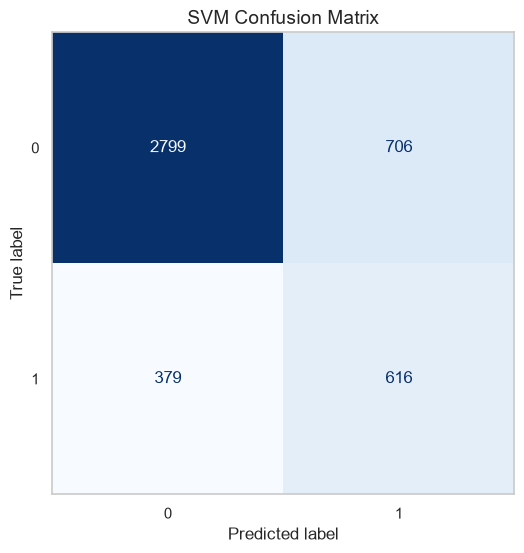

In [43]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_svm,
    display_labels=[0, 1],
    cmap='Blues',
    colorbar=False,
    ax=plt.gca()
)
plt.title('SVM Confusion Matrix', fontsize=14)
plt.grid(False)
plt.show()

### Hyperparameter Tuning for XGBoost (Best Performing Model)

Now that XGBoost has been identified as our top-performing base model, we use **GridSearchCV** with 3-fold cross-validation to fine-tune its hyperparameters and squeeze out the best possible performance.

* **Objective:** Optimize key parameters (such as `learning_rate`, `max_depth`, and `n_estimators`) to maximize **Recall**.
* **Why Recall?** In credit default prediction, catching risky customers who are likely to default is critical for minimizing financial risk, even if it means tolerating a few more false positives.

In [44]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

# 1. Define the base model with your class balance handling
base_xgb = XGBClassifier(
    scale_pos_weight=scale_pos_weight_val,
    random_state=42,
    n_jobs=-1
)

# 2. Set up the hyperparameter grid to explore

param_grid = {
    'n_estimators': [200, 500, 750],
    'max_depth': [3, 5],
    'learning_rate': [0.03, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'min_child_weight': [1, 5]
}


# 3. Configure GridSearchCV (using 3-fold cross-validation and F1 scoring)
grid_search = GridSearchCV(
    estimator=base_xgb,
    param_grid=param_grid,
    scoring='recall',        # Focuses on optimizing the F1-score for defaults
    cv=3,                # 3-fold cross validation
    verbose=1,
    n_jobs=-1
)

# 4. Run the grid search on your training data
print("Running Grid Search for XGBoost...")
grid_search.fit(X_train, y_train)

# 5. Output the results
print("\nBest Parameters Found:")
print(grid_search.best_params_)
print(f"Best Cross-Validation Recall: {grid_search.best_score_:.4f}")


Running Grid Search for XGBoost...
Fitting 3 folds for each of 96 candidates, totalling 288 fits



Best Parameters Found:
{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 200, 'subsample': 0.8}
Best Cross-Validation Recall: 0.6498


# Evaluate Tuned XGBoost Model on Validation Data

Now that our grid search is complete, we extract the optimal model configuration (`best_estimator_`) and test its performance against our unseen validation dataset (`X_val`).

* **Model Extraction:** Pulls the best hyperparameter set found during the grid search.
* **Performance Metrics:** Generates a full classification report (precision, recall, F1-score) and calculates the **ROC-AUC score** to measure how effectively the tuned model separates defaulting customers from non-defaulting ones.

In [45]:
best_xgb = grid_search.best_estimator_

# Evaluate the tuned model on validation data
y_val_pred_grid = best_xgb.predict(X_val)
y_val_prob_grid = best_xgb.predict_proba(X_val)[:, 1]

print("\nBest Grid Search Model - Validation Results:")
print(classification_report(y_val, y_val_pred_grid))
print(f"Validation ROC-AUC: {roc_auc_score(y_val, y_val_prob_grid):.4f}")


Best Grid Search Model - Validation Results:
              precision    recall  f1-score   support

           0       0.88      0.78      0.83      3505
           1       0.45      0.64      0.53       995

    accuracy                           0.75      4500
   macro avg       0.67      0.71      0.68      4500
weighted avg       0.79      0.75      0.76      4500

Validation ROC-AUC: 0.7700


# Evaluate the best XGBoost model on test data

In [46]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, accuracy_score

# Make predictions on test data
y_test_pred = best_xgb.predict(X_test)
y_test_prob = best_xgb.predict_proba(X_test)[:, 1]

# Display results
print("Best Grid Search Model - Test Results:\n")

print("Classification Report:")
print(classification_report(y_test, y_test_pred))

print(f"Test Accuracy: {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, y_test_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))


Best Grid Search Model - Test Results:

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.77      0.82      3505
           1       0.44      0.62      0.52       995

    accuracy                           0.74      4500
   macro avg       0.66      0.70      0.67      4500
weighted avg       0.78      0.74      0.76      4500

Test Accuracy: 0.7411
Test ROC-AUC: 0.7690

Confusion Matrix:
[[2715  790]
 [ 375  620]]


# Confusion matrix to visualize correct vs. incorrect predictions on the validation set

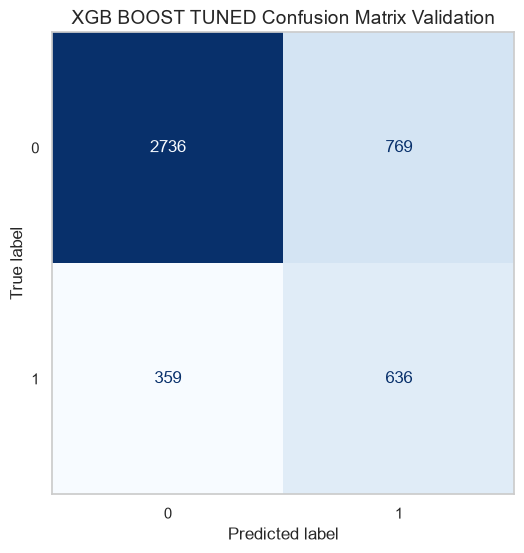

In [47]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_grid,
    display_labels=[0, 1],
    cmap='Blues',
    colorbar=False,
    ax=plt.gca()
)
plt.title('XGB BOOST TUNED Confusion Matrix Validation', fontsize=14)
plt.grid(False)
plt.show()

# Confusion matrix for the final test dataset to evaluate unseen performance

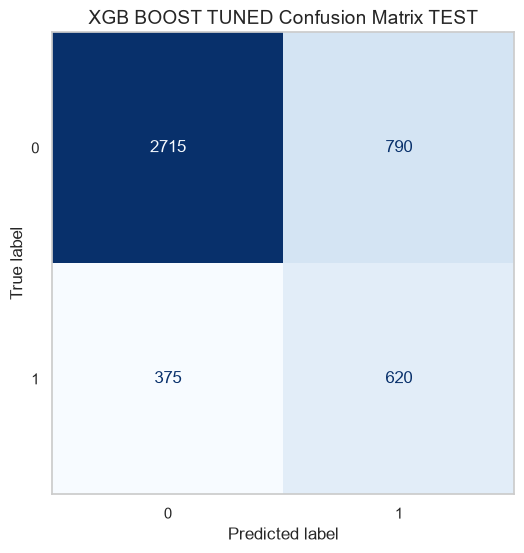

In [48]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    display_labels=[0, 1],
    cmap='Blues',
    colorbar=False,
    ax=plt.gca()
)
plt.title('XGB BOOST TUNED Confusion Matrix TEST', fontsize=14)
plt.grid(False)
plt.show()

# Save the model files the backend uses

The tuned XGBoost model is saved to `backend/models/risk_model/`, which is part of the
repository, so the backend can score customers as soon as it is cloned:

| File | What it holds | Used by |
|---|---|---|
| `model.json` | The model, in XGBoost's own portable format (no pickle, so no version lock-in) | every prediction |
| `metadata.json` | Feature names in model order, threshold, best parameters, validation and test scores, data sizes, library versions | the backend checks the features and shows the scores |
| `data_split.csv` | Which customers were train / validation / test | the customer page says if a prediction is an independent test |

After running this notebook, score the customers in the database with
`python -m app.manage score-customers` (from `backend/`).

In [49]:
import json
import platform
from datetime import datetime, timezone

import xgboost
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

MODEL_DIR = Path("../backend/models/risk_model")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
THRESHOLD = 0.5


def scores(y_true, probability):
    predicted = (probability >= THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        "customers": int(len(y_true)),
        "accuracy": float(accuracy_score(y_true, predicted)),
        "precision": float(precision_score(y_true, predicted, zero_division=0)),
        "recall": float(recall_score(y_true, predicted, zero_division=0)),
        "f1": float(f1_score(y_true, predicted, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, probability)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


best_xgb.save_model(MODEL_DIR / "model.json")

metadata = {
    "model_name": "XGBoost (tuned)",
    "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "target": "default payment next month",
    "features": list(X_train.columns),
    "threshold": THRESHOLD,
    "best_params": grid_search.best_params_,
    "metrics": {
        "threshold": THRESHOLD,
        "validation": scores(y_val, best_xgb.predict_proba(X_val)[:, 1]),
        "test": scores(y_test, best_xgb.predict_proba(X_test)[:, 1]),
    },
    "data": {"customers": int(len(df)), "train": int(len(X_train)),
             "validation": int(len(X_val)), "test": int(len(X_test))},
    "libraries": {"python": platform.python_version(), "xgboost": xgboost.__version__,
                  "scikit-learn": sklearn.__version__, "pandas": pd.__version__},
}
(MODEL_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

split = pd.concat([
    pd.DataFrame({"ID": customer_ids.loc[part.index], "split": name})
    for name, part in (("train", X_train), ("validation", X_val), ("test", X_test))
]).sort_values("ID")
split.to_csv(MODEL_DIR / "data_split.csv", index=False)

# The saved model must give the same probabilities when loaded the way the backend loads it.
booster = xgboost.Booster()
booster.load_model(MODEL_DIR / "model.json")
reloaded = booster.predict(xgboost.DMatrix(X_test.astype(float).to_numpy(), feature_names=list(X_test.columns)))
assert np.allclose(reloaded, best_xgb.predict_proba(X_test)[:, 1], atol=1e-6)

print("Saved to", MODEL_DIR.resolve())
print("Features:", metadata["features"])
print("Test:", {k: round(v, 4) for k, v in metadata["metrics"]["test"].items() if isinstance(v, float)})

Saved to D:\NIAI\ComplyAgent\ComplyAgent-langchain\backend\models\risk_model
Features: ['LIMIT_BAL', 'AGE', 'on_time_payment_rate', 'avg_payment_delay', 'avg_credit_utilization', 'EDUCATION_cleaned', 'sex_male']
Test: {'accuracy': 0.7411, 'precision': 0.4397, 'recall': 0.6231, 'f1': 0.5156, 'roc_auc': 0.769}
